# Fraud Detection Hackathon – Categorical EDA (Percentages)

This notebook mirrors the categorical exploratory analysis, but plots all bar charts on a percentage scale without line plots.

## Objectives
- Reuse the cleaning pipeline for categorical variables.
- Display side-by-side bar charts where the y-axis shows the share of transactions per label.
- Omit line charts while preserving mutual-information scoring.

In [1]:
# Imports and global configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

In [2]:
# Load training data
DATA_PATH = "data/train.csv"
raw_df = pd.read_csv(DATA_PATH)

print(f"Raw shape: {raw_df.shape}")
display(raw_df.head())

Raw shape: (195401, 16)


,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,label,suspicious_activity_score
0,181852054,2022-06-02 15:28:13,611.03,payment_method_2,SA,SA,avs_code_8,NaN,NaN,returning,E,05/2025,mastercard,credit,0.0,7.801596
1,181265052,2022-05-21 15:53:20,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,S,NaN,NaN,NaN,0.0,8.117476
2,149633145,2021-09-30 09:05:06,611.85,payment_method_1,HK,HK,avs_code_1,NaN,NaN,returning,E;E,NaN,NaN,NaN,0.0,6.240885
3,149158895,2021-09-22 15:19:15,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,E,03/2023,visa,debit,0.0,5.188745
4,169664695,2022-02-18 08:59:32,434.71,payment_method_3,HK,HK,avs_code_5,NaN,NaN,returning,E,NaN,NaN,NaN,0.0,5.738602


## Data Cleaning Strategy
The same cleaning steps are applied as in the count-based notebook to guarantee comparability:

1. Drop duplicate `order_id` rows.
2. Remove rows with missing labels or unparseable `order_date` values.
3. Fill categorical NaNs with `'Unknown'` and numeric NaNs with the column median.

In [3]:
# Apply cleaning strategy
clean_df = raw_df.copy()

initial_rows = len(clean_df)
clean_df = clean_df.drop_duplicates(subset="order_id")
duplicates_removed = initial_rows - len(clean_df)

label_missing = clean_df["label"].isna().sum()
if label_missing:
    clean_df = clean_df.dropna(subset=["label"])
    print(f"Dropped {label_missing} rows with missing label.")

clean_df["order_date"] = pd.to_datetime(clean_df["order_date"], errors="coerce")
invalid_dates = clean_df["order_date"].isna().sum()
if invalid_dates:
    clean_df = clean_df.dropna(subset=["order_date"])
    print(f"Dropped {invalid_dates} rows where `order_date` could not be parsed.")

categorical_cols = clean_df.select_dtypes(include="object").columns.tolist()
categorical_cols = [col for col in categorical_cols if col != "order_id"]

numeric_cols = clean_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [col for col in numeric_cols if col != "label"]

for col in categorical_cols:
    if clean_df[col].isna().any():
        clean_df[col] = clean_df[col].fillna("Unknown")

median_imputations = {}
for col in numeric_cols:
    if clean_df[col].isna().any():
        median_value = clean_df[col].median()
        clean_df[col] = clean_df[col].fillna(median_value)
        median_imputations[col] = median_value

print(f"Rows removed as duplicates: {duplicates_removed}")
print(f"Final cleaned shape: {clean_df.shape}")
print("Numeric columns imputed with median:", median_imputations if median_imputations else "None")

missing_summary = clean_df.isna().sum()
if missing_summary.sum() == 0:
    print("Remaining missing values per column: None")
else:
    display(missing_summary[missing_summary > 0])

Dropped 5 rows with missing label.
Rows removed as duplicates: 5135
Final cleaned shape: (190261, 16)
Numeric columns imputed with median: {'email_amount_spent_avg_180d': np.float64(459.94375), 'email_orders_count_180d': np.float64(4.0)}
Remaining missing values per column: None


In [4]:
# Identify categorical features (excluding order_id and temporal fields)
excluded_categoricals = {"order_id"}
if "order_date" in clean_df.columns:
    excluded_categoricals.add("order_date")

categorical_features = [
    col for col in clean_df.columns
    if clean_df[col].dtype == "object" and col not in excluded_categoricals
]

print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

summary_rows = []
for col in categorical_features:
    value_counts = clean_df[col].value_counts()
    summary_rows.append({
        "feature": col,
        "unique_values": value_counts.shape[0],
        "top_category": value_counts.index[0],
        "top_category_pct": (value_counts.iloc[0] / len(clean_df)) * 100
    })

categorical_summary = pd.DataFrame(summary_rows).sort_values("unique_values")
display(categorical_summary)

Categorical features (9): ['payment_method', 'billing_address_country_code', 'shipping_address_country_code', 'avs_code', 'session_visitor_type', 'shipping_method_type', 'card_expiration_date', 'bin_brand', 'bin_type']


,feature,unique_values,top_category,top_category_pct
4,session_visitor_type,3,returning,70.734412
8,bin_type,4,credit,42.203079
0,payment_method,9,payment_method_2,69.113481
7,bin_brand,11,visa,33.970703
3,avs_code,25,avs_code_4,24.038558
5,shipping_method_type,156,E,46.003648
2,shipping_address_country_code,167,GB,15.426703
1,billing_address_country_code,167,GB,15.208582
6,card_expiration_date,188,Unknown,30.981126


In [5]:
# Helper utilities for percentage-based plots
PALETTE = {'Label 0': "#1f77b4", 'Label 1': "#ff7f0e"}

def summarise_categorical_feature(dataframe, feature, top_n=12):
    working = dataframe[[feature, "label"]].copy()
    working[feature] = working[feature].fillna("Unknown")
    top_categories = working[feature].value_counts().nlargest(top_n).index
    working.loc[~working[feature].isin(top_categories), feature] = "Other"
    working[feature] = working[feature].astype(str)

    overall_counts = (
        working[feature]
        .value_counts()
        .rename_axis(feature)
        .reset_index(name="total_count")
    )

    label_counts = (
        working.groupby([feature, "label"])
        .size()
        .reset_index(name="count")
        .pivot(index=feature, columns="label", values="count")
        .fillna(0)
        .astype(int)
    )

    for label_value in [0, 1]:
        if label_value not in label_counts.columns:
            label_counts[label_value] = 0

    label_counts = label_counts[[0, 1]].reindex(overall_counts[feature])
    label_counts["overall"] = label_counts[0] + label_counts[1]

    total_count_all_categories = label_counts["overall"].sum()
    percentage_table = pd.DataFrame({
        "label_0_pct": (label_counts[0] / label_counts["overall"]) * 100,
        "label_1_pct": (label_counts[1] / label_counts["overall"]) * 100,
        "overall_pct": (label_counts["overall"] / total_count_all_categories) * 100
    })

    summary_table = overall_counts.merge(
        label_counts.reset_index(), on=feature, how="left"
    ).merge(
        percentage_table.reset_index(), on=feature, how="left"
    )

    return summary_table, percentage_table

def plot_categorical_feature(dataframe, feature, top_n=12):
    summary_table, percentage_table = summarise_categorical_feature(dataframe, feature, top_n=top_n)
    category_order = summary_table[feature].tolist()

    print(f"\nFeature: {feature}")
    display(summary_table)

    plotting_df = percentage_table.reset_index().melt(
        id_vars=feature,
        value_vars=["label_0_pct", "label_1_pct"],
        var_name="label",
        value_name="percentage"
    )
    plotting_df["label"] = plotting_df["label"].map({
        "label_0_pct": "Label 0",
        "label_1_pct": "Label 1"
    })

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=plotting_df,
        x=feature,
        y="percentage",
        hue="label",
        hue_order=["Label 0", "Label 1"],
        palette=PALETTE,
        order=category_order
    )
    plt.title(f"Percentage distribution by label – {feature}")
    plt.xlabel(feature)
    plt.ylabel('percentage')
    plt.xticks(rotation=45)
    plt.ylim(0, 100)
    plt.legend(title="Label")
    plt.tight_layout()
    plt.show()


Feature: payment_method


,payment_method,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,payment_method_2,131496,114158,17338,131496,86.814808,13.185192,69.113481
1,payment_method_1,34798,34798,0,34798,100.000000,0.000000,18.289613
2,payment_method_3,19654,19552,102,19654,99.481022,0.518978,10.330020
3,payment_method_4,3417,3406,11,3417,99.678080,0.321920,1.795954
4,Unknown,610,606,4,610,99.344262,0.655738,0.320612
5,payment_method_7,126,126,0,126,100.000000,0.000000,0.066225
6,payment_method_5,115,112,3,115,97.391304,2.608696,0.060443
7,payment_method_6,29,27,2,29,93.103448,6.896552,0.015242
8,payment_method_8,16,13,3,16,81.250000,18.750000,0.008410


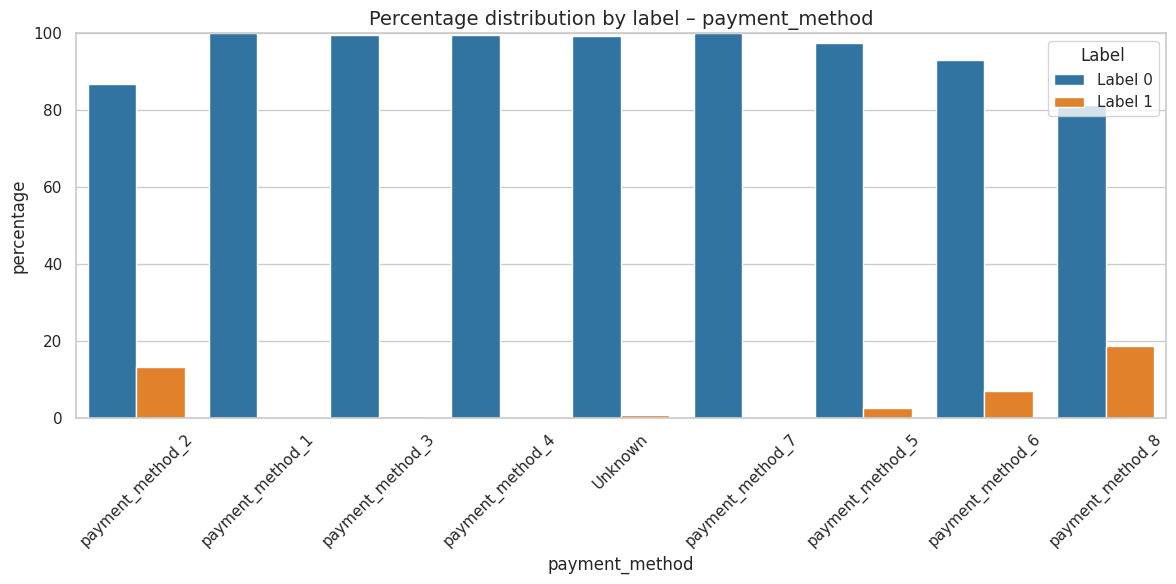


Feature: billing_address_country_code


,billing_address_country_code,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,Other,68108,57441,10667,68108,84.338110,15.661890,35.797142
1,GB,28936,28295,641,28936,97.784766,2.215234,15.208582
2,RU,13748,13240,508,13748,96.304917,3.695083,7.225863
3,US,12422,11249,1173,12422,90.557076,9.442924,6.528926
4,DE,10448,9993,455,10448,95.645100,4.354900,5.491404
5,IT,9278,8797,481,9278,94.815693,5.184307,4.876459
6,MX,8341,7463,878,8341,89.473684,10.526316,4.383978
7,AU,7618,7282,336,7618,95.589394,4.410606,4.003973
8,JP,7284,6576,708,7284,90.280066,9.719934,3.828425
9,FR,6956,6575,381,6956,94.522714,5.477286,3.656030


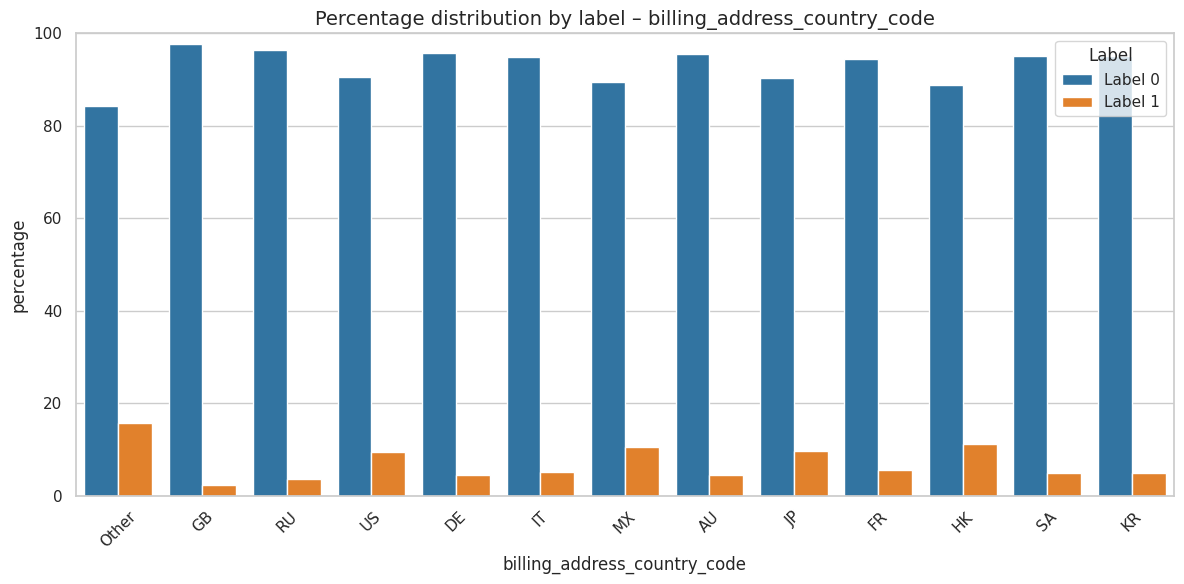


Feature: shipping_address_country_code


,shipping_address_country_code,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,Other,68186,57523,10663,68186,84.361892,15.638108,35.838138
1,GB,29351,28652,699,29351,97.618480,2.381520,15.426703
2,RU,13798,13269,529,13798,96.166111,3.833889,7.252143
3,US,11317,10215,1102,11317,90.262437,9.737563,5.948145
4,DE,10440,10062,378,10440,96.379310,3.620690,5.487199
5,IT,9426,8929,497,9426,94.727350,5.272650,4.954247
6,MX,8462,7573,889,8462,89.494209,10.505791,4.447575
7,AU,7604,7279,325,7604,95.725934,4.274066,3.996615
8,JP,7321,6611,710,7321,90.301871,9.698129,3.847872
9,FR,7062,6655,407,7062,94.236760,5.763240,3.711743


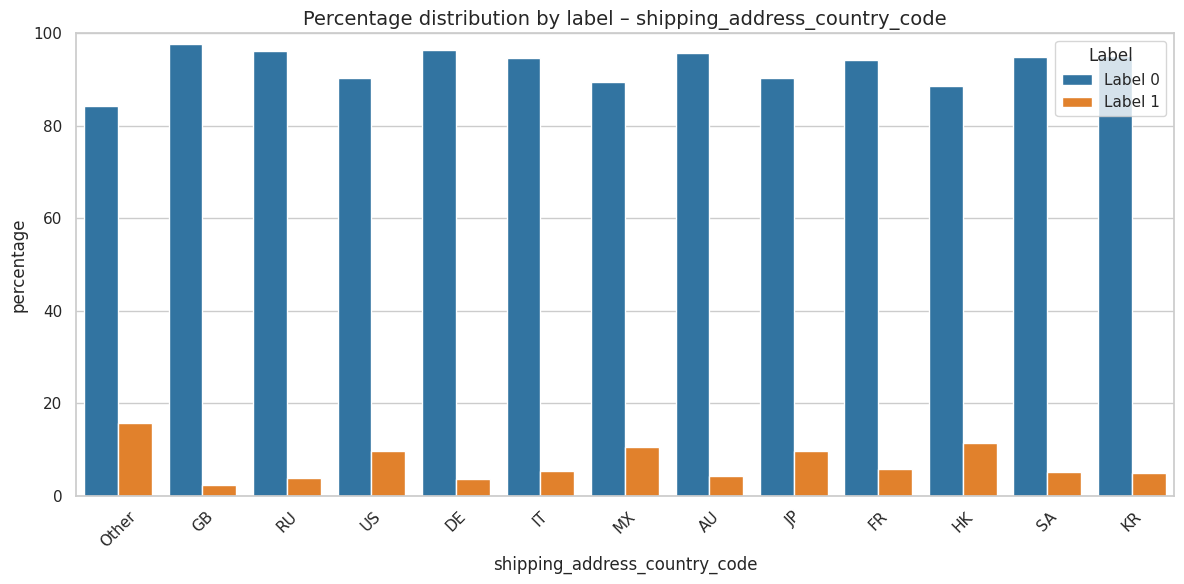


Feature: avs_code


,avs_code,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,avs_code_4,45736,41916,3820,45736,91.647717,8.352283,24.038558
1,avs_code_1,39143,39080,63,39143,99.839052,0.160948,20.573318
2,avs_code_5,32844,29816,3028,32844,90.780660,9.219340,17.262602
3,avs_code_3,21244,18760,2484,21244,88.307287,11.692713,11.165714
4,avs_code_6,10125,8880,1245,10125,87.703704,12.296296,5.321637
5,avs_code_8,9518,7891,1627,9518,82.906073,17.093927,5.002602
6,avs_code_2,7039,6804,235,7039,96.661458,3.338542,3.699655
7,avs_code_10,7002,4107,2895,7002,58.654670,41.345330,3.680208
8,Other,4048,3462,586,4048,85.523715,14.476285,2.127604
9,avs_code_7,3904,3724,180,3904,95.389344,4.610656,2.051918


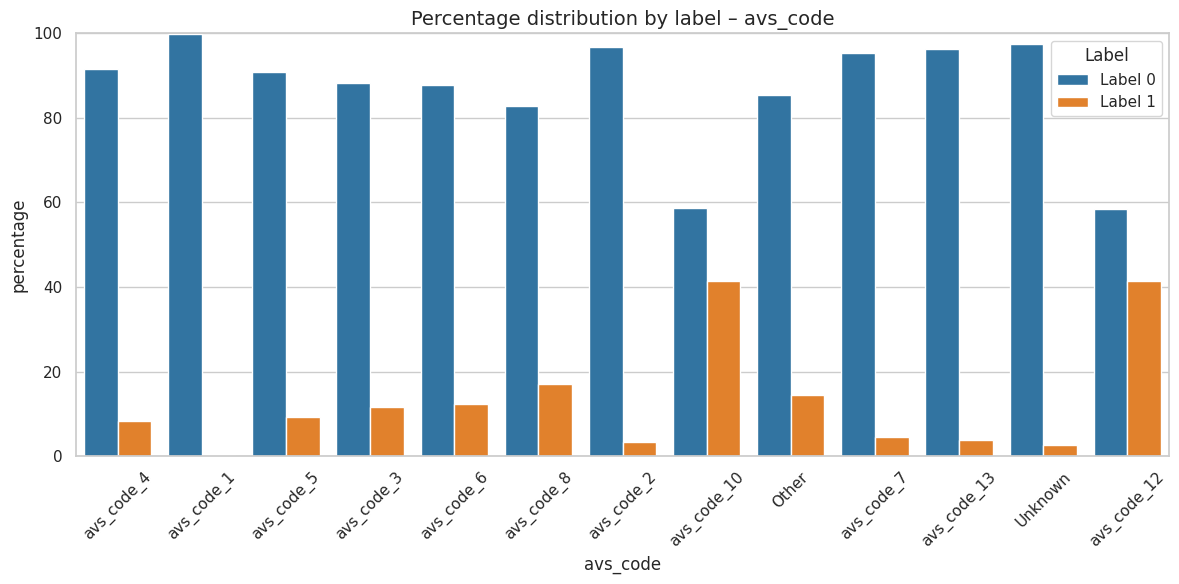


Feature: session_visitor_type


,session_visitor_type,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,returning,134580,125234,9346,134580,93.055432,6.944568,70.734412
1,Unknown,34839,32692,2147,34839,93.837366,6.162634,18.311162
2,new,20842,14872,5970,20842,71.355916,28.644084,10.954426


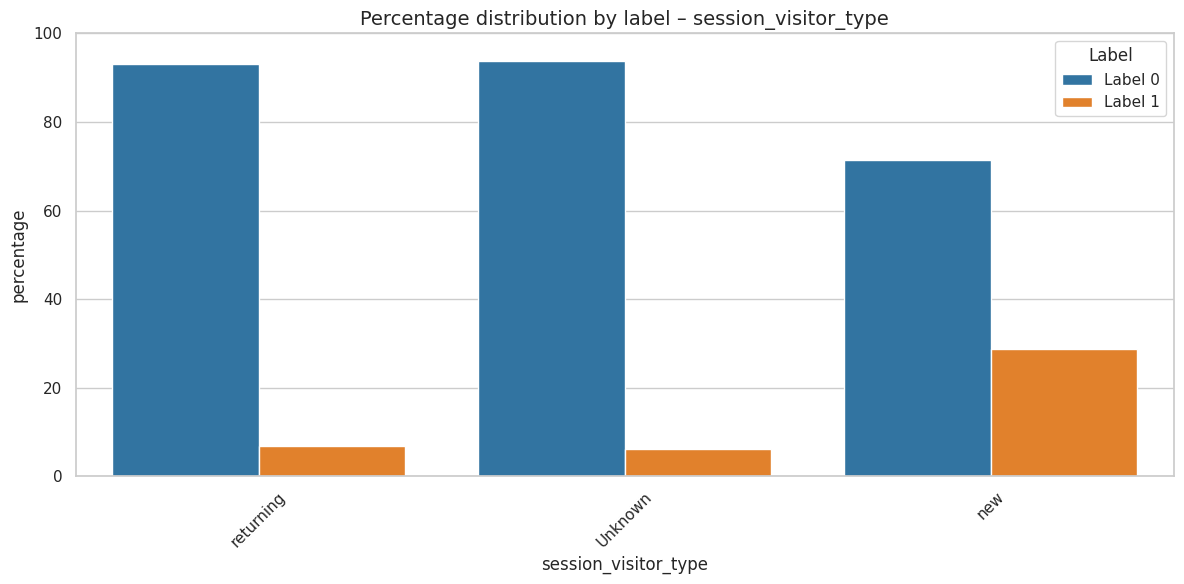


Feature: shipping_method_type


,shipping_method_type,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,E,87527,76326,11201,87527,87.202806,12.797194,46.003648
1,S,51763,47249,4514,51763,91.279485,8.720515,27.206311
2,E;E,19875,19213,662,19875,96.669182,3.330818,10.446177
3,S;S,8671,8453,218,8671,97.485872,2.514128,4.557424
4,E;E;E,7406,7320,86,7406,98.838779,1.161221,3.892548
5,E;E;E;E,3586,3452,134,3586,96.263246,3.736754,1.884779
6,Other,3374,3187,187,3374,94.457617,5.542383,1.773353
7,S;S;S,2694,2618,76,2694,97.178916,2.821084,1.415950
8,E;E;E;E;E,1770,1693,77,1770,95.649718,4.350282,0.930301
9,S;S;S;S,1201,1030,171,1201,85.761865,14.238135,0.631238


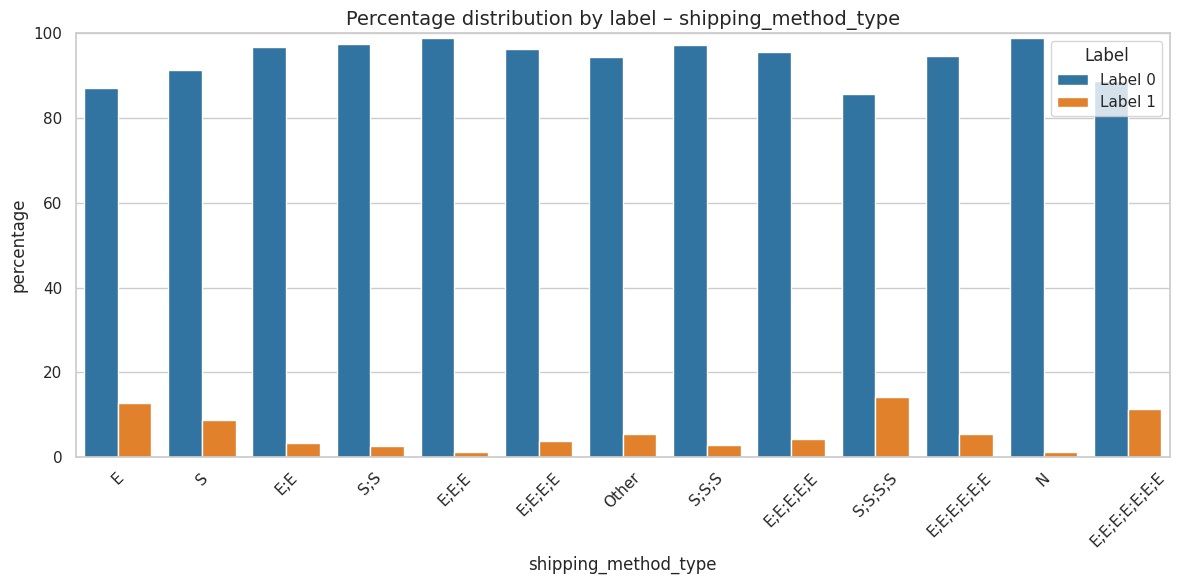


Feature: card_expiration_date


,card_expiration_date,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,Other,102783,88356,14427,102783,85.963632,14.036368,54.022106
1,Unknown,58945,58860,85,58945,99.855798,0.144202,30.981126
2,09/2024,2902,2616,286,2902,90.144728,9.855272,1.525273
3,10/2024,2829,2524,305,2829,89.218805,10.781195,1.486905
4,03/2024,2748,2481,267,2748,90.283843,9.716157,1.444332
5,06/2024,2647,2416,231,2647,91.273139,8.726861,1.391247
6,11/2024,2609,2289,320,2609,87.734764,12.265236,1.371274
7,08/2024,2537,2284,253,2537,90.027592,9.972408,1.333431
8,09/2023,2510,2367,143,2510,94.302789,5.697211,1.319240
9,10/2023,2504,2182,322,2504,87.140575,12.859425,1.316087


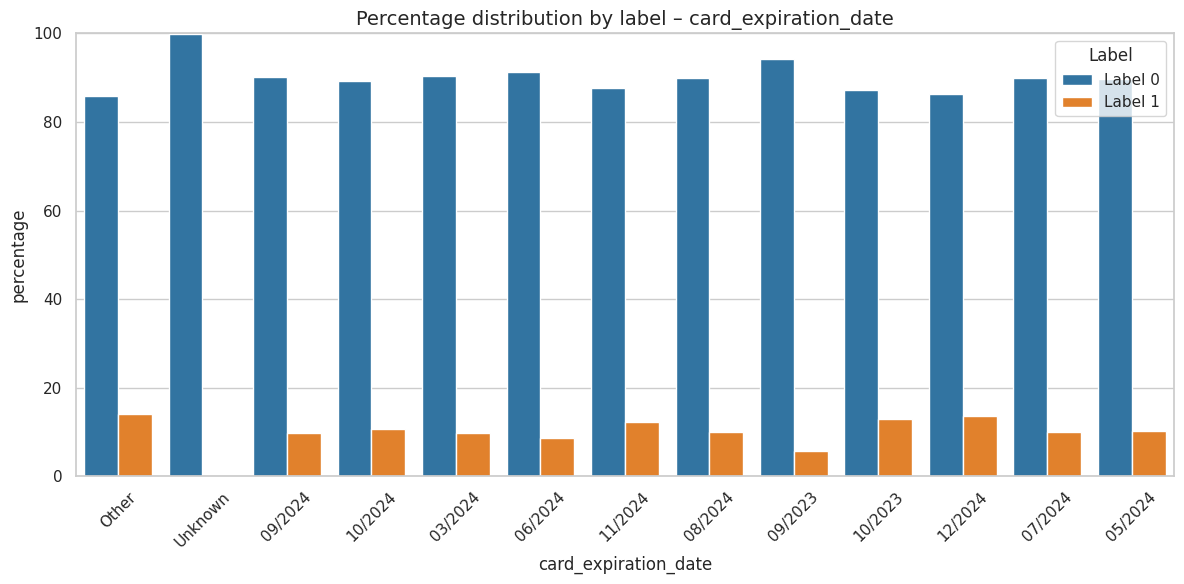


Feature: bin_brand


,bin_brand,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,visa,64633,57993,6640,64633,89.726610,10.273390,33.970703
1,Unknown,60002,59538,464,60002,99.226692,0.773308,31.536679
2,mastercard,52250,42359,9891,52250,81.069856,18.930144,27.462276
3,amex,11297,10988,309,11297,97.264761,2.735239,5.937633
4,jcb,1009,915,94,1009,90.683845,9.316155,0.530324
5,china unionpay,448,433,15,448,96.651786,3.348214,0.235466
6,diners club,219,209,10,219,95.433790,4.566210,0.115105
7,discover,171,143,28,171,83.625731,16.374269,0.089877
8,maestro,130,128,2,130,98.461538,1.538462,0.068327
9,mir,87,81,6,87,93.103448,6.896552,0.045727


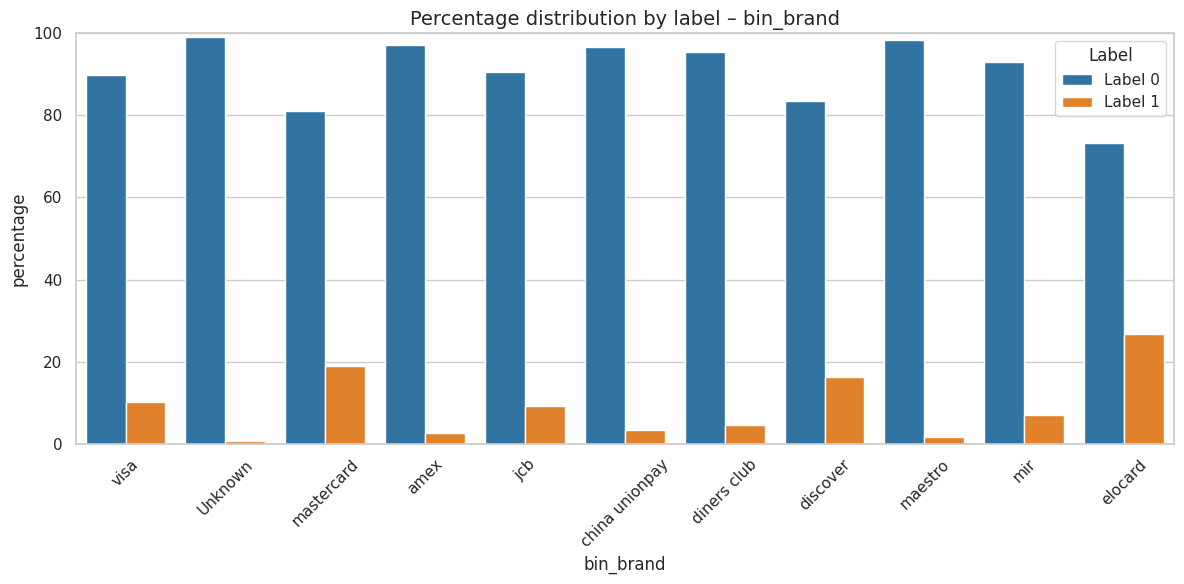


Feature: bin_type


,bin_type,total_count,0.0,1.0,overall,label_0_pct,label_1_pct,overall_pct
0,credit,80296,65306,14990,80296,81.331573,18.668427,42.203079
1,Unknown,60408,59815,593,60408,99.018342,0.981658,31.750070
2,debit,49529,47651,1878,49529,96.208282,3.791718,26.032135
3,credit/debit,28,26,2,28,92.857143,7.142857,0.014717


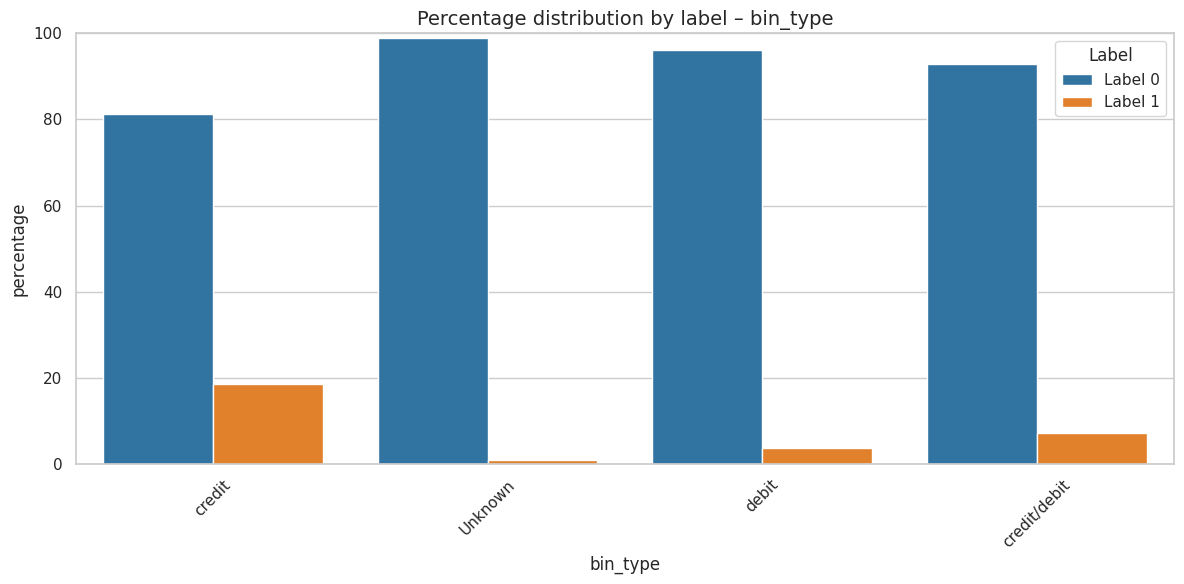

In [6]:
# Generate percentage-based visuals for every categorical feature
for feature in categorical_features:
    plot_categorical_feature(clean_df, feature, top_n=12)

In [7]:
# Mutual information scores (unchanged)
encoded_df = pd.DataFrame({
    col: clean_df[col].astype("category").cat.codes
    for col in categorical_features
})

mi_scores = mutual_info_classif(
    encoded_df,
    clean_df["label"].astype(int),
    discrete_features=True,
    random_state=42,
)

mi_report = (
    pd.DataFrame({
        "feature": categorical_features,
        "mutual_information": mi_scores,
    })
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

print("Mutual information (higher is more informative about the fraud label):")
display(mi_report)

Mutual information (higher is more informative about the fraud label):


,feature,mutual_information
0,card_expiration_date,0.051093
1,bin_type,0.043959
2,avs_code,0.043278
3,billing_address_country_code,0.037343
4,bin_brand,0.036387
5,shipping_address_country_code,0.036384
6,payment_method,0.033156
7,session_visitor_type,0.020268
8,shipping_method_type,0.012760


## Notes
- Percentages for each category sum to 100% across the two labels.
- The `overall_pct` column in the summary tables indicates the share of total transactions represented by each category.
- Consider adjusting `top_n` if you need more or fewer categories per chart.